# COMP9417 Project: starter notebook

This notebook loads the dataset, shows how day D and day D+1 are defined, builds a day-ahead
table for both targets, and computes the two required baselines by year. It ends with a very
simple model trained on 2010-2013 so you can see the evaluation protocol in action.

Run it from the kit's root folder, with the libraries in `requirements.txt` installed.

In [37]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "harness")
import dayahead as da          # the same helpers the marking runner uses

df = da.load_dataset("data/nem_weather_halfhourly_2010_2026.csv")
print(df.shape, df.index.min(), "to", df.index.max())
df.head()

(295104, 18) 2010-01-01 00:30:00 to 2026-11-01 00:00:00


,nsw_demand,nsw_price,qld_demand,qld_price,vic_demand,vic_price,syd_temp,syd_rh,syd_cloud,syd_solar,mel_temp,mel_rh,mel_cloud,mel_solar,bne_temp,bne_rh,bne_cloud,bne_solar
timestamp,,,,,,,,,,,,,,,,,,
2010-01-01 00:30:00,7809.31,21.50,5422.25,20.67,5111.02,20.11,21.20,95.5,72.5,0.0,27.15,54.0,52.0,0.0,22.50,82.5,97.5,0.0
2010-01-01 01:00:00,7483.69,20.98,5315.98,20.15,4960.03,19.40,21.10,96.0,87.0,0.0,26.80,56.0,21.0,0.0,22.30,83.0,95.0,0.0
2010-01-01 01:30:00,7117.23,20.06,5186.70,18.95,5283.40,19.63,21.05,96.0,87.0,0.0,26.35,59.0,11.0,0.0,22.25,83.0,95.0,0.0
2010-01-01 02:00:00,6812.03,17.93,5050.83,16.88,5046.15,17.05,21.00,96.0,87.0,0.0,25.90,62.0,1.0,0.0,22.20,83.0,95.0,0.0
2010-01-01 02:30:00,6544.33,17.43,4924.74,16.28,4796.18,15.84,21.00,96.5,84.5,0.0,25.50,64.5,4.5,0.0,22.20,83.0,96.0,0.0


## Timestamps and days

Each timestamp marks the **end** of a half-hour interval, in market time (AEST, UTC+10, no
daylight saving). Day D is made of the 48 intervals stamped D 00:30, D 01:00, ..., D 23:30 and
D+1 00:00. `da.market_day` maps each timestamp to its day.

In [38]:
df["day"] = da.market_day(df.index)
df["period"] = ((df.index - pd.Timedelta("30min")).hour * 2
                + (df.index - pd.Timedelta("30min")).minute // 30)   # 0..47
df[["day", "period", "nsw_demand", "nsw_price"]].iloc[44:52]

,day,period,nsw_demand,nsw_price
timestamp,,,,
2010-01-01 22:30:00,2010-01-01,44,8210.54,21.70
2010-01-01 23:00:00,2010-01-01,45,8041.77,22.27
2010-01-01 23:30:00,2010-01-01,46,7782.68,21.50
2010-01-02 00:00:00,2010-01-01,47,7574.85,21.00
2010-01-02 00:30:00,2010-01-02,0,7343.30,20.67
2010-01-02 01:00:00,2010-01-02,1,7099.73,19.27
2010-01-02 01:30:00,2010-01-02,2,6779.80,17.92
2010-01-02 02:00:00,2010-01-02,3,6497.47,15.63


## A first look at drift

Midday demand has fallen as rooftop solar has grown, while the evening peak has not.
Negative prices were almost unknown before 2020.

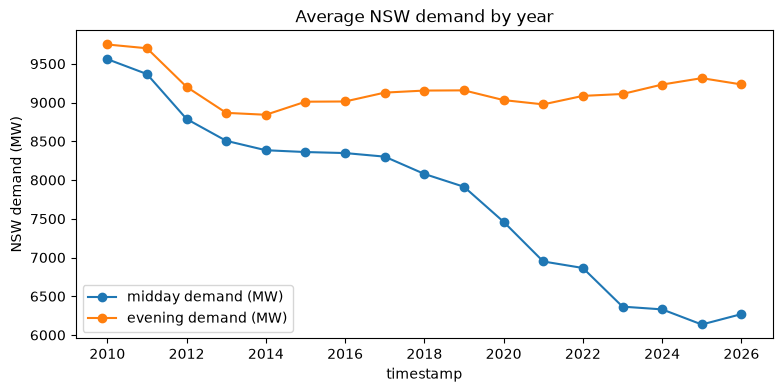

,midday demand (MW),evening demand (MW),negative-price share (%)
timestamp,,,
2010,9559.5,9748.6,0.0
2011,9367.2,9700.0,0.0
2012,8787.5,9201.8,0.0
2013,8505.7,8866.7,0.0
2014,8384.3,8841.9,0.0
2015,8361.0,9010.5,0.0
2016,8347.8,9013.4,0.0
2017,8301.6,9127.8,0.0
2018,8078.2,9154.2,0.0


In [39]:
year = df.index.year
noon = df["period"].isin([23, 24, 25, 26])      # 11:30-13:30
evening = df["period"].isin([37, 38, 39])       # 18:30-20:00
summary = pd.DataFrame({
    "midday demand (MW)": df.loc[noon, "nsw_demand"].groupby(year[noon]).mean(),
    "evening demand (MW)": df.loc[evening, "nsw_demand"].groupby(year[evening]).mean(),
    "negative-price share (%)": (df["nsw_price"] < 0).groupby(year).mean() * 100,
}).round(1)
ax = summary[["midday demand (MW)", "evening demand (MW)"]].plot(marker="o", figsize=(9, 4))
ax.set_ylabel("NSW demand (MW)"); ax.set_title("Average NSW demand by year")
plt.show()
summary

## The day-ahead table

One row per half-hour of day D+1. Targets: demand (MW), and whether the price is above
the mean price of day D. Inputs here are only examples: values from day D and day D-6
(same half-hour yesterday and last week) and the weather for D+1. Designing better inputs is
part of your work. Everything is shifted by whole days, so no information from D+1's market
values leaks into the inputs.

In [40]:
daily_price_mean = df.groupby("day")["nsw_price"].transform("mean")
t = pd.DataFrame(index=df.index)
t["day"], t["period"] = df["day"], df["period"]
t["y_demand"] = df["nsw_demand"]
t["y_up"] = (df["nsw_price"] > daily_price_mean.shift(48)).astype(int)
t["demand_lag1"] = df["nsw_demand"].shift(48)         # same half-hour yesterday
t["demand_lag7"] = df["nsw_demand"].shift(48 * 7)     # same half-hour last week
t["up_lag1"] = (df["nsw_price"].shift(48) > daily_price_mean.shift(48)).astype(int)
t["up_lag7"] = (df["nsw_price"].shift(48 * 7) > daily_price_mean.shift(48)).astype(int)  # vs day D mean
for c in da.WEATHER_COLS:
    t[c] = df[c]                                      # weather of D+1 itself (allowed)
t = t.iloc[48 * 7:].dropna()
t["year"] = t["day"].dt.year
t.head()

,day,period,y_demand,y_up,demand_lag1,demand_lag7,up_lag1,up_lag7,syd_temp,syd_rh,...,syd_solar,mel_temp,mel_rh,mel_cloud,mel_solar,bne_temp,bne_rh,bne_cloud,bne_solar,year
timestamp,,,,,,,,,,,,,,,,,,,,,
2010-01-08 00:30:00,2010-01-08,0,7498.35,0,7433.46,7809.31,0,0,20.95,74.5,...,0.0,15.20,87.0,0.0,0.0,22.90,88.0,98.5,0.0,2010
2010-01-08 01:00:00,2010-01-08,1,7242.52,0,7216.30,7483.69,0,0,20.90,75.0,...,0.0,14.70,89.0,0.0,0.0,22.70,88.0,99.0,0.0,2010
2010-01-08 01:30:00,2010-01-08,2,6972.24,0,6940.48,7117.23,0,0,20.85,75.5,...,0.0,14.00,91.5,0.0,0.0,22.35,89.5,99.0,0.0,2010
2010-01-08 02:00:00,2010-01-08,3,6706.22,0,6692.82,6812.03,0,0,20.80,76.0,...,0.0,13.30,94.0,0.0,0.0,22.00,91.0,99.0,0.0,2010
2010-01-08 02:30:00,2010-01-08,4,6525.71,0,6477.56,6544.33,0,0,20.80,76.5,...,0.0,13.25,94.0,0.0,0.0,21.95,92.0,99.5,0.0,2010


## Baselines by year

Both baselines must be reported in your project. They are hard to beat.

In [41]:
def yearly(t, pred_demand, pred_up):
    g = t.assign(pd_=pred_demand, pu_=pred_up).groupby("year")
    return pd.DataFrame({
        "MAPE (%)": g.apply(lambda x: da.mape(x.y_demand, x.pd_)),
        "balanced acc. (%)": g.apply(lambda x: da.balanced_accuracy(x.y_up, x.pu_)),
    }).round(2)

base1 = yearly(t, t.demand_lag1, t.up_lag1)
base7 = yearly(t, t.demand_lag7, t.up_lag7)
pd.concat({"same half-hour yesterday": base1, "same half-hour last week": base7}, axis=1)

same half-hour yesterday                   same half-hour last week  \
                     MAPE (%) balanced acc. (%)                 MAPE (%)   
year                                                                       
2010                     4.92             78.60                     4.91   
2011                     4.76             76.17                     5.22   
2012                     5.04             73.31                     4.81   
2013                     5.29             74.63                     5.52   
2014                     4.93             73.99                     4.93   
2015                     5.35             74.72                     5.76   
2016                     5.46             69.83                     5.84   
2017                     5.95             68.71                     6.23   
2018                     5.20             72.26                     6.34   
2019                     5.75             71.53                     6.53   
2020                     5.89             72.26                     7.15   
2021                     5.73             72.85                     7.17   
2022                     5.89             70.82                     7.28   
2023                     6.46             76.00                     7.90   
2024                     7.30             76.39                     9.29   
2025                     8.07             79.42                    10.55   
2026                     6.89             73.87                     9.35   

                        
     balanced acc. (%)  
year                    
2010             74.44  
2011             74.18  
2012             69.98  
2013             72.44  
2014             74.28  
2015             72.06  
2016             67.56  
2017             68.30  
2018             69.10  
2019             69.10  
2020             69.94  
2021             69.26  
2022             67.41  
2023             73.31  
2024             72.48  
2025             75.40  
2026             70.20

## The protocol with a very simple model

Train on 2010-2013, validate on 2014, then freeze the model and evaluate every later year.
This ridge regression is only an illustration; the project asks for at least two algorithms per
task, from different families, with justified features.

Validation (2014) MAPE: 4.08%


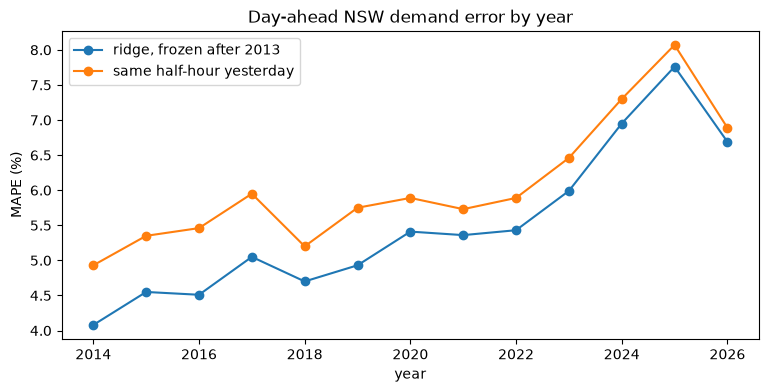

In [42]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

feats = ["demand_lag1", "demand_lag7", "syd_temp", "syd_solar", "period"]
X = t[feats].assign(sin_p=np.sin(2 * np.pi * t.period / 48), cos_p=np.cos(2 * np.pi * t.period / 48))
train, valid = t.year <= 2013, t.year == 2014
model = make_pipeline(StandardScaler(), Ridge()).fit(X[train], t.y_demand[train])
print(f"Validation (2014) MAPE: {da.mape(t.y_demand[valid], model.predict(X[valid])):.2f}%")

frozen = yearly(t, model.predict(X), t.up_lag1)["MAPE (%)"]
ax = pd.DataFrame({"ridge, frozen after 2013": frozen, "same half-hour yesterday": base1["MAPE (%)"]}
                  ).loc[2014:].plot(marker="o", figsize=(9, 4))
ax.set_ylabel("MAPE (%)"); ax.set_title("Day-ahead NSW demand error by year")
plt.show()

## Next steps

* `example_package/` shows a complete model package (`model.py`, `train.py`, `artifacts/`).
* `template/model.py` is a blank Forecaster to start from.
* `python check_submission.py your_package` runs your package exactly as in marking.

In [43]:
t["price_lag1"] = df["nsw_price"].shift(48).loc[t.index]
t["price_lag7"] = df["nsw_price"].shift(48 * 7).loc[t.index]

daily_price_mean = df.groupby("day")["nsw_price"].transform("mean")

t["previous_mean_price"] = daily_price_mean.shift(48).loc[t.index]

In [131]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Select features
features = [
    "demand_lag1",
    "price_lag1",
    "previous_mean_price",
    "syd_temp",
    "syd_solar",
    "syd_rh",
    "up_lag1",
    "up_lag7"
]

X = t[features].copy()
y = t["y_up"]

# Day of week: Monday = 0, Sunday = 6
day_of_week = t["day"].dt.day_of_week

# One-hot encode day of week
dow_features = pd.get_dummies(
    day_of_week,
    prefix="dow",
    dtype=int
)

X = pd.concat([X, dow_features], axis=1)

# Cyclic encoding of time of day
X["sin_period"] = np.sin(2 * np.pi * t["period"] / 48)
X["cos_period"] = np.cos(2 * np.pi * t["period"] / 48)

# Cyclic encoding of time of year
day_of_year = t["day"].dt.day_of_year

X["sin_year"] = np.sin(2 * np.pi * day_of_year / 365.25)
X["cos_year"] = np.cos(2 * np.pi * day_of_year / 365.25)

# Encoding demand and price data with time of day and time of year
X["demand_sin_period"] = X["demand_lag1"] * X["sin_period"]
X["demand_cos_period"] = X["demand_lag1"] * X["cos_period"]

X["price_sin_period"] = X["price_lag1"] * X["sin_period"]
X["price_cos_period"] = X["price_lag1"] * X["cos_period"]

X["demand_sin_year"] = X["demand_lag1"] * X["sin_year"]
X["demand_cos_year"] = X["demand_lag1"] * X["cos_year"]

X["price_sin_year"] = X["price_lag1"] * X["sin_year"]
X["price_cos_year"] = X["price_lag1"] * X["cos_year"]

# Non linear features
X["temp_squared"] = t["syd_temp"] ** 2

X["temp_sin_period"] = (
    t["syd_temp"] * X["sin_period"]
)
X["temp_cos_period"] = (
    t["syd_temp"] * X["cos_period"]
)

X["price_relative_mean"] = (
    t["price_lag1"] - t["previous_mean_price"]
)

X["demand_pct_change"] = (
    (t["demand_lag1"] - t["demand_lag7"])
    / t["demand_lag7"].clip(lower=1)
)

# Solar radiation and time-of-day interaction
X["solar_sin_period"] = X["syd_solar"] * X["sin_period"]
X["solar_cos_period"] = X["syd_solar"] * X["cos_period"]

# Previous day's price direction × time of day
X["up_lag1_sin_period"] = X["up_lag1"] * X["sin_period"]
X["up_lag1_cos_period"] = X["up_lag1"] * X["cos_period"]

# Previous day's price direction × season
X["up_lag1_sin_year"] = X["up_lag1"] * X["sin_year"]
X["up_lag1_cos_year"] = X["up_lag1"] * X["cos_year"]

X["up_lag1_lag7"] = X["up_lag1"] * X["up_lag7"]

X["up_lag1_price_relative"] = (
    X["up_lag1"] *
    (X["price_lag1"] - X["previous_mean_price"])
)

for day in range(1, 7):
    X[f"up_lag1_dow_{day}"] = (
        X["up_lag1"] * X[f"dow_{day}"]
    )

# Chronological split
train = t["year"] <= 2013
valid = t["year"] == 2014

# Create model
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000)
)

# Train
log_model.fit(X[train], y[train])

# Predict on validation set
y_pred = log_model.predict(X[valid])

# Evaluate
print("Logistic Regression")
print("Accuracy:", accuracy_score(y[valid], y_pred))
print("Balanced accuracy:",
      da.balanced_accuracy(y[valid], y_pred))


Logistic Regression
Accuracy: 0.7925799086757991
Balanced accuracy: 79.27622368105882


In [134]:
baseline1 = t.loc[valid, "up_lag1"]
baseline7 = t.loc[valid, "up_lag7"]

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Yesterday Baseline",
        "Last Week Baseline"
    ],
    "Accuracy (%)": [
        accuracy_score(y[valid], y_pred) * 100,
        accuracy_score(y[valid], baseline1) * 100,
        accuracy_score(y[valid], baseline7) * 100
    ],
    "Balanced Accuracy (%)": [
        da.balanced_accuracy(y[valid], y_pred),
        da.balanced_accuracy(y[valid], baseline1),
        da.balanced_accuracy(y[valid], baseline7)
    ]
})

display(results.round(2))

,Model,Accuracy (%),Balanced Accuracy (%)
0,Logistic Regression,79.26,79.28
1,Yesterday Baseline,73.90,73.99
2,Last Week Baseline,74.25,74.28


In [135]:
# Train final frozen model on 2010–2014
train_frozen = t["year"] <= 2014

frozen_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000)
)

frozen_model.fit(
    X.loc[train_frozen],
    y.loc[train_frozen]
)

# Evaluate on 2015–2026
test = (t["year"] >= 2015) & (t["year"] <= 2026)

pred = frozen_model.predict(X.loc[test])

# Store predictions and actual labels
results = pd.DataFrame({
    "year": t.loc[test, "year"],
    "actual": y.loc[test],
    "predicted": pred
})

# Yearly evaluation
yearly_results = []

for year, group in results.groupby("year"):
    yearly_results.append({
        "Year": year,
        "Accuracy": accuracy_score(
            group["actual"], group["predicted"]
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            group["actual"], group["predicted"]
        ),
        "Class 1 Proportion": group["actual"].mean()
    })

yearly_df = pd.DataFrame(yearly_results)
print(yearly_df)

    Year  Accuracy  Balanced Accuracy  Class 1 Proportion
0   2015  0.782934           0.782212            0.457363
1   2016  0.755464           0.739758            0.396289
2   2017  0.740297           0.730867            0.421062
3   2018  0.768436           0.757794            0.403710
4   2019  0.760331           0.748217            0.404224
5   2020  0.758994           0.746594            0.386669
6   2021  0.742180           0.725430            0.412842
7   2022  0.701027           0.695974            0.482363
8   2023  0.754909           0.747543            0.459018
9   2024  0.761555           0.745996            0.433231
10  2025  0.776769           0.769770            0.464041
11  2026  0.715118           0.718913            0.519120


<Axes: title={'center': 'Frozen Logistic Regression Performance'}, xlabel='Year'>

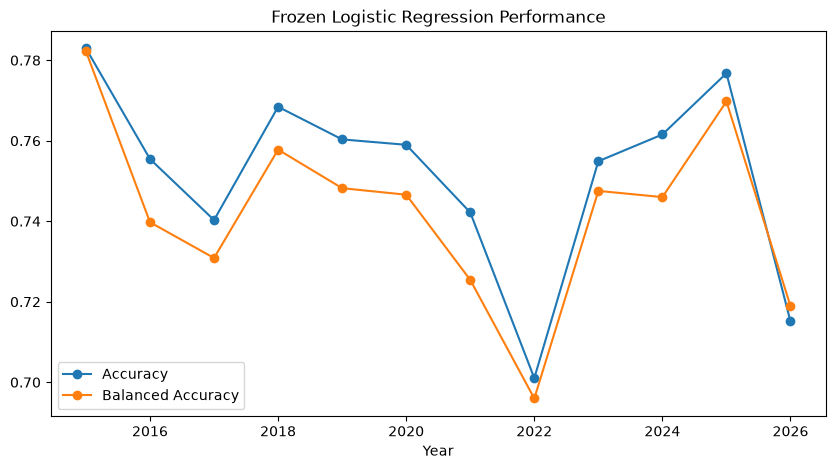

In [136]:
yearly_df.plot(
    x="Year",
    y=["Accuracy", "Balanced Accuracy"],
    marker="o",
    figsize=(10, 5),
    title="Frozen Logistic Regression Performance"
)

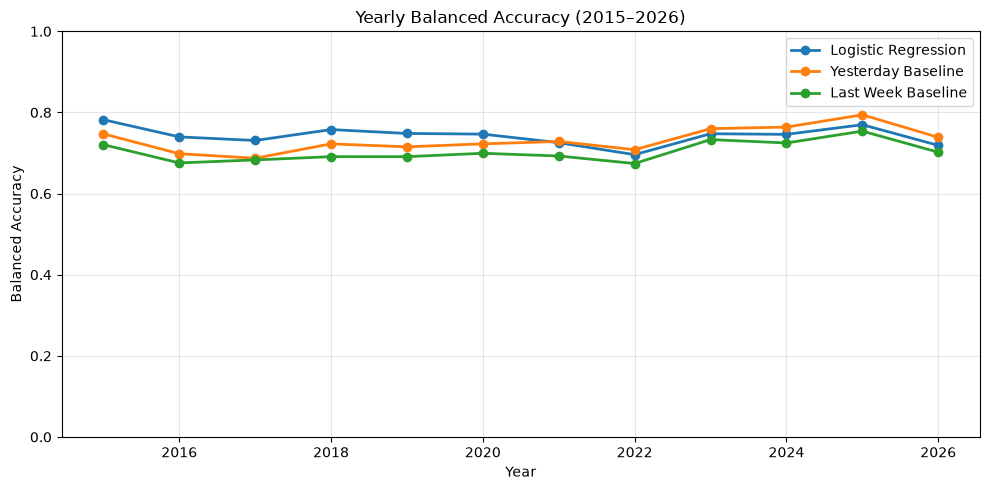

In [137]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score

# Historical simulation period
test = (t["year"] >= 2015) & (t["year"] <= 2026)

# Predictions
results = pd.DataFrame({
    "Year": t.loc[test, "year"],
    "Actual": y.loc[test],
    "Logistic Regression": frozen_model.predict(X.loc[test]),
    "Yesterday Baseline": t.loc[test, "up_lag1"],
    "Last Week Baseline": t.loc[test, "up_lag7"]
})

# Calculate yearly balanced accuracy
yearly_results = []

for year, group in results.groupby("Year"):
    yearly_results.append({
        "Year": year,
        "Logistic Regression": balanced_accuracy_score(
            group["Actual"], group["Logistic Regression"]
        ),
        "Yesterday Baseline": balanced_accuracy_score(
            group["Actual"], group["Yesterday Baseline"]
        ),
        "Last Week Baseline": balanced_accuracy_score(
            group["Actual"], group["Last Week Baseline"]
        )
    })

yearly_df = pd.DataFrame(yearly_results)

# Plot
ax = yearly_df.plot(
    x="Year",
    y=["Logistic Regression", "Yesterday Baseline", "Last Week Baseline"],
    marker="o",
    figsize=(10, 5),
    linewidth=2
)

ax.set_title("Yearly Balanced Accuracy (2015–2026)")
ax.set_xlabel("Year")
ax.set_ylabel("Balanced Accuracy")
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

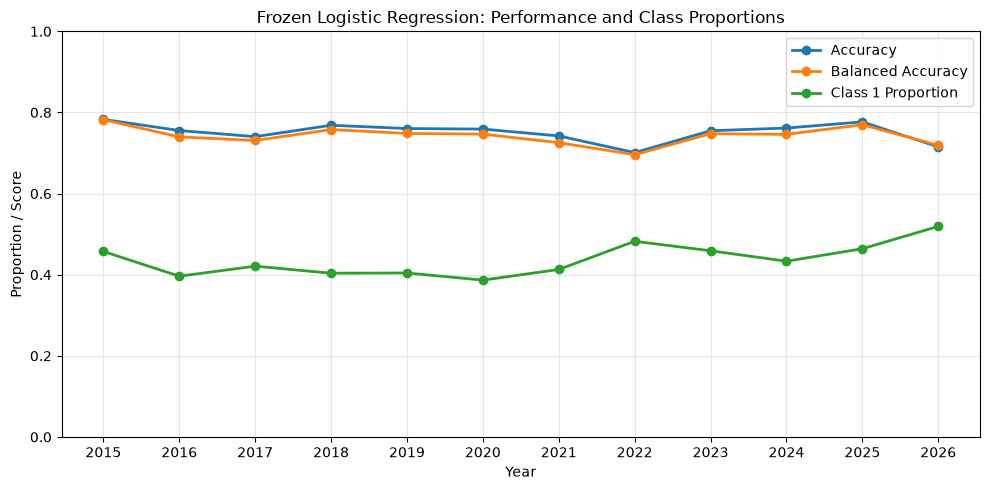

In [138]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Historical simulation period
test = (t["year"] >= 2015) & (t["year"] <= 2026)

# Predictions from frozen logistic regression
pred = frozen_model.predict(X.loc[test])

# Create results DataFrame
results = pd.DataFrame({
    "year": t.loc[test, "year"].to_numpy(),
    "actual": y.loc[test].to_numpy(),
    "predicted": pred
})

# Calculate metrics for each year
yearly_results = []

for year, group in results.groupby("year"):
    yearly_results.append({
        "Year": year,
        "Accuracy": accuracy_score(
            group["actual"],
            group["predicted"]
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            group["actual"],
            group["predicted"]
        ),
        "Class 1 Proportion": group["actual"].mean()
    })

yearly_df = pd.DataFrame(yearly_results)

# Plot
ax = yearly_df.plot(
    x="Year",
    y=["Accuracy", "Balanced Accuracy", "Class 1 Proportion"],
    marker="o",
    figsize=(10, 5),
    linewidth=2
)

ax.set_title("Frozen Logistic Regression: Performance and Class Proportions")
ax.set_xlabel("Year")
ax.set_ylabel("Proportion / Score")
ax.set_ylim(0, 1)
ax.set_xticks(yearly_df["Year"])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

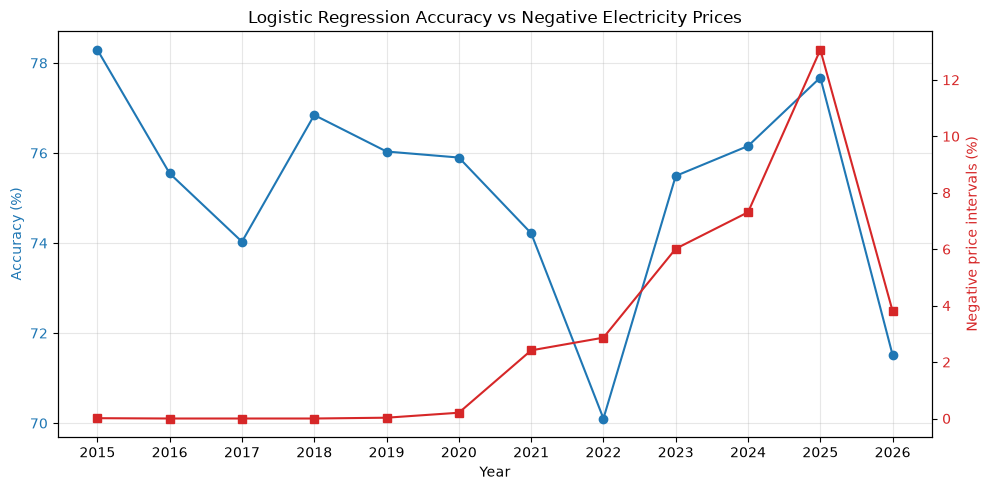

Correlation: 0.11296114926939538


In [143]:

from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

# Negative-price percentage by year (from original dataset)
negative_pct = (
    (df["nsw_price"] < 0)
    .groupby(df["day"].dt.year)
    .mean() * 100
)

# Model accuracy by year
results = []

for year in range(2015, 2027):
    mask = t["year"] == year

    if not mask.any():
        continue

    pred = frozen_model.predict(X.loc[mask])
    accuracy = accuracy_score(y.loc[mask], pred) * 100

    results.append({
        "Year": year,
        "Accuracy": accuracy,
        "Negative Prices": negative_pct.loc[year]
    })

results = pd.DataFrame(results)

# Plot
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(results["Year"], results["Accuracy"],
         "o-", color="tab:blue", label="Accuracy")
ax1.set_xlabel("Year")
ax1.set_ylabel("Accuracy (%)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(results["Year"], results["Negative Prices"],
         "s-", color="tab:red", label="Negative prices")
ax2.set_ylabel("Negative price intervals (%)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

ax1.set_xticks(results["Year"])
ax1.grid(alpha=0.3)
plt.title("Logistic Regression Accuracy vs Negative Electricity Prices")
plt.tight_layout()
plt.show()

# Correlation
print("Correlation:",
      results["Accuracy"].corr(results["Negative Prices"]))




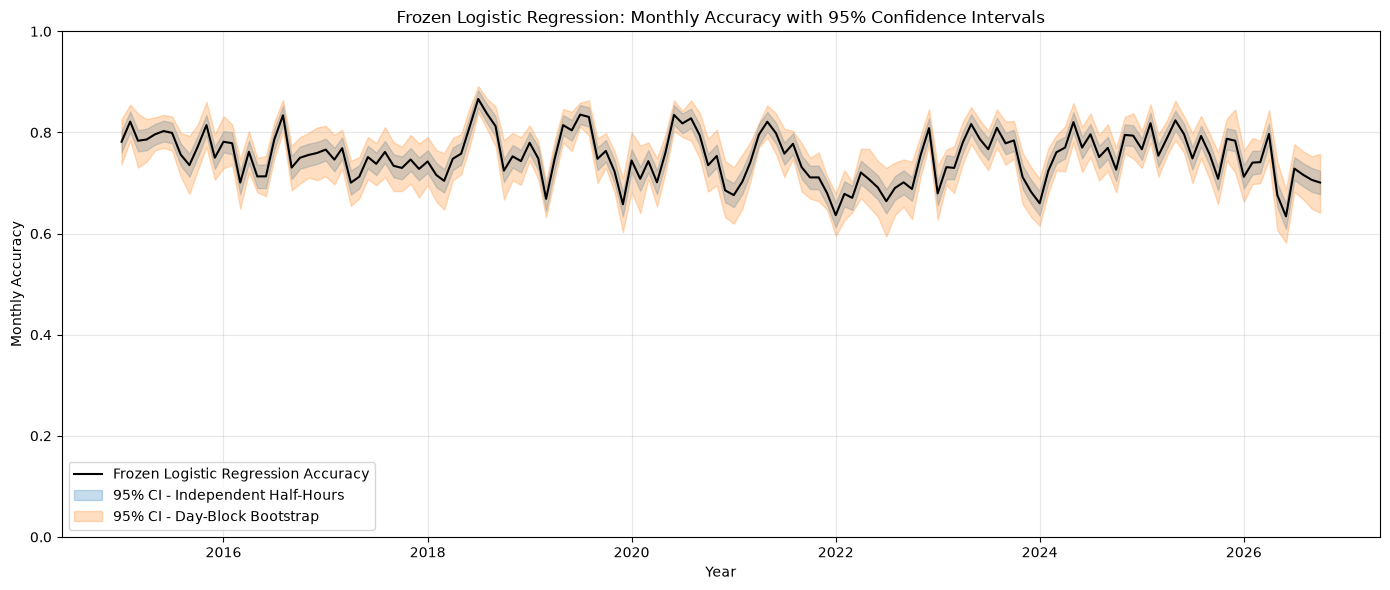

Average independent CI width: 0.043946300416295
Average bootstrap CI width: 0.08751752450184978


,accuracy,ind_lower,ind_upper,boot_lower,boot_upper,ind_width,boot_width
month,,,,,,,
2015-01-01,0.7816,0.7606,0.8026,0.7365,0.8266,0.0420,0.0901
2015-02-01,0.8214,0.8010,0.8419,0.7842,0.8549,0.0410,0.0707
2015-03-01,0.7836,0.7627,0.8045,0.7305,0.8374,0.0418,0.1069
2015-04-01,0.7861,0.7649,0.8073,0.7424,0.8264,0.0424,0.0840
2015-05-01,0.7964,0.7759,0.8168,0.7648,0.8300,0.0409,0.0652
...,...,...,...,...,...,...,...
2026-06-01,0.6340,0.6091,0.6589,0.5819,0.6875,0.0498,0.1056
2026-07-01,0.7285,0.7059,0.7511,0.6828,0.7769,0.0452,0.0941
2026-08-01,0.7164,0.6935,0.7393,0.6680,0.7628,0.0458,0.0948


In [140]:
# --------------------------------------------------
# 1. Get frozen model predictions
# --------------------------------------------------

test = (t["year"] >= 2015) & (t["year"] <= 2026)

results = t.loc[test, ["day"]].copy()
results["actual"] = y.loc[test].to_numpy()
results["predicted"] = frozen_model.predict(X.loc[test])

results["day"] = pd.to_datetime(results["day"])
results["month"] = results["day"].dt.to_period("M")

# Correct prediction indicator (1 = correct, 0 = incorrect)
results["correct"] = (
    results["actual"] == results["predicted"]
).astype(int)


# --------------------------------------------------
# 2. Calculate both confidence intervals
# --------------------------------------------------

def monthly_confidence_intervals(group, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)

    correct = group["correct"].to_numpy()
    n = len(correct)

    # Monthly accuracy
    accuracy = correct.mean()

    # Method 1: Independent half-hours (binomial normal CI)
    se = np.sqrt(accuracy * (1 - accuracy) / n)

    independent_lower = max(0, accuracy - 1.96 * se)
    independent_upper = min(1, accuracy + 1.96 * se)

    # Method 2: Day-block bootstrap
    days = [
        day_group["correct"].to_numpy()
        for _, day_group in group.groupby("day")
    ]

    n_days = len(days)
    bootstrap_accuracies = []

    for _ in range(n_boot):
        sampled_indices = rng.integers(0, n_days, size=n_days)

        sampled_correct = np.concatenate([
            days[i] for i in sampled_indices
        ])

        bootstrap_accuracies.append(sampled_correct.mean())

    bootstrap_lower, bootstrap_upper = np.percentile(
        bootstrap_accuracies, [2.5, 97.5]
    )

    return pd.Series({
        "accuracy": accuracy,
        "ind_lower": independent_lower,
        "ind_upper": independent_upper,
        "boot_lower": bootstrap_lower,
        "boot_upper": bootstrap_upper
    })


monthly = results.groupby("month").apply(
    monthly_confidence_intervals,
    include_groups=False
)

monthly.index = monthly.index.to_timestamp()


# --------------------------------------------------
# 3. Plot monthly accuracy with both 95% CIs
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly.index,
    monthly["accuracy"],
    color="black",
    linewidth=1.5,
    label="Frozen Logistic Regression Accuracy"
)

ax.fill_between(
    monthly.index,
    monthly["ind_lower"],
    monthly["ind_upper"],
    color="tab:blue",
    alpha=0.25,
    label="95% CI - Independent Half-Hours"
)

ax.fill_between(
    monthly.index,
    monthly["boot_lower"],
    monthly["boot_upper"],
    color="tab:orange",
    alpha=0.25,
    label="95% CI - Day-Block Bootstrap"
)

ax.set_xlabel("Year")
ax.set_ylabel("Monthly Accuracy")
ax.set_title(
    "Frozen Logistic Regression: Monthly Accuracy "
    "with 95% Confidence Intervals"
)

ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Compare confidence interval widths
# --------------------------------------------------

monthly["ind_width"] = (
    monthly["ind_upper"] - monthly["ind_lower"]
)

monthly["boot_width"] = (
    monthly["boot_upper"] - monthly["boot_lower"]
)

print("Average independent CI width:",
      monthly["ind_width"].mean())

print("Average bootstrap CI width:",
      monthly["boot_width"].mean())

display(monthly.round(4))


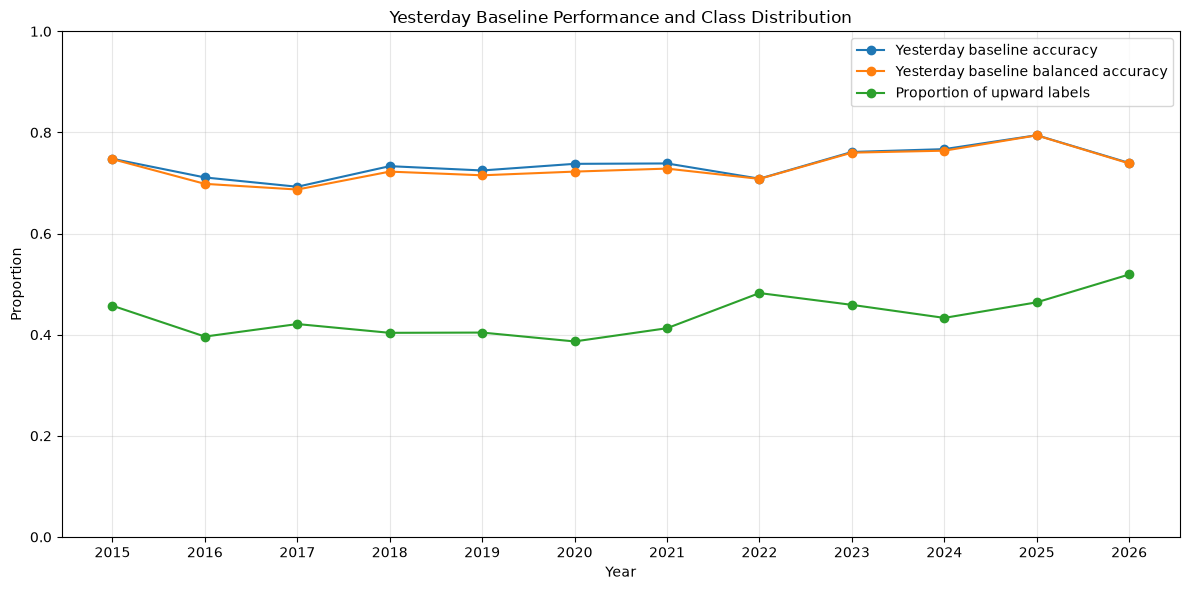

,accuracy,balanced_accuracy,proportion_up
year,,,
2015,0.7479,0.7472,0.4574
2016,0.7110,0.6983,0.3963
2017,0.6926,0.6871,0.4211
2018,0.7333,0.7226,0.4037
2019,0.7248,0.7153,0.4042
2020,0.7379,0.7226,0.3867
2021,0.7387,0.7285,0.4128
2022,0.7086,0.7082,0.4824
2023,0.7614,0.7600,0.4590


In [144]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Historical simulation period
test = t.loc[
    (t["year"] >= 2015) & (t["year"] <= 2026)
].copy()

# Remove rows with missing labels or lagged predictions
test = test.dropna(subset=["y_up", "up_lag1"])

# Calculate yearly metrics
results = []

for year, group in test.groupby("year"):
    y_true = group["y_up"]
    y_pred = group["up_lag1"]

    results.append({
        "year": year,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "proportion_up": y_true.mean()
    })

yearly = pd.DataFrame(results).set_index("year")

# Plot
plt.figure(figsize=(12, 6))

plt.plot(
    yearly.index,
    yearly["accuracy"],
    marker="o",
    label="Yesterday baseline accuracy"
)

plt.plot(
    yearly.index,
    yearly["balanced_accuracy"],
    marker="o",
    label="Yesterday baseline balanced accuracy"
)

plt.plot(
    yearly.index,
    yearly["proportion_up"],
    marker="o",
    label="Proportion of upward labels"
)

plt.xlabel("Year")
plt.ylabel("Proportion")
plt.title("Yesterday Baseline Performance and Class Distribution")
plt.xticks(yearly.index)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

display(yearly.round(4))